# Сценарій 1. Статистика Школи №89

In [1]:
import matplotlib.pyplot as plt

from models import load_school

school = load_school("Школа №89", "data/classes.csv", "data/students.csv")
print("Класів:", len(school.classes))
print("Учнів:", len(school.all_students()))

Класів: 32
Учнів: 841


## Статистика

In [2]:
school.print_statistics()

a) Загальна кількість учнів: 841
b) Хлопці: 53.5 %, дівчата: 46.5 %
c) Середня кількість учнів у класі: 26.3
d) Максимальна кількість учнів: 31 (2В, 4А)
e) Мінімальна кількість учнів: 18 (10Б)


## Графіки

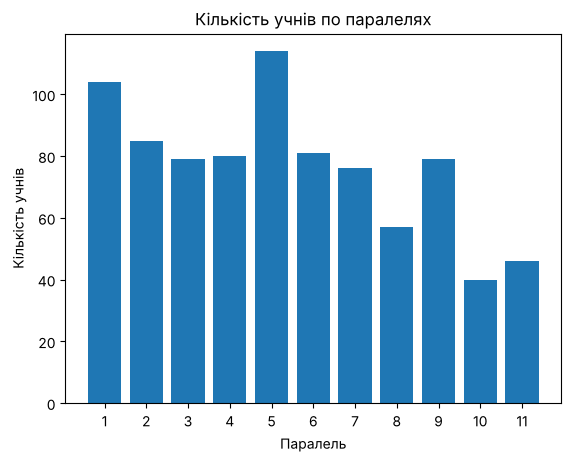

In [3]:
# a) кількість учнів по паралелях
grades = list(range(1, 12))
counts = [sum(len(c) for c in school.classes if c.grade == g) for g in grades]
plt.bar(grades, counts)
plt.xticks(grades)
plt.title("Кількість учнів по паралелях")
plt.xlabel("Паралель")
plt.ylabel("Кількість учнів")
plt.show()

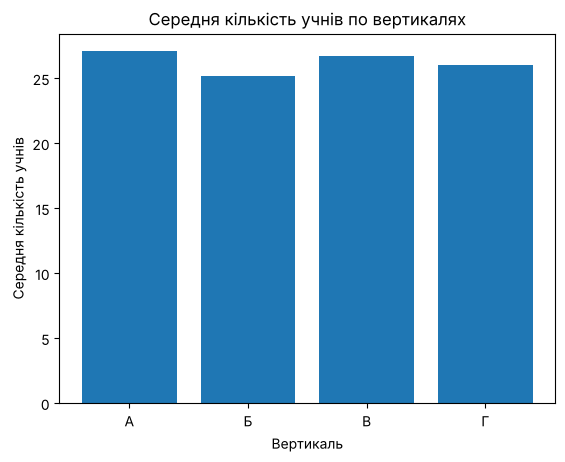

In [4]:
# b) середня кількість учнів по вертикалях
letters = sorted({c.letter for c in school.classes})
averages = []
for letter in letters:
    sizes = [len(c) for c in school.classes if c.letter == letter]
    averages.append(sum(sizes) / len(sizes))
plt.bar(letters, averages)
plt.title("Середня кількість учнів по вертикалях")
plt.xlabel("Вертикаль")
plt.ylabel("Середня кількість учнів")
plt.show()

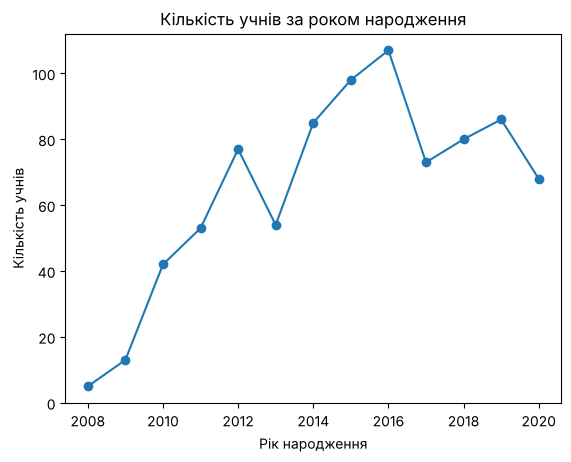

In [5]:
# c) кількість учнів за роком народження
students = school.all_students()
years = sorted({s.birth_year for s in students})
counts = [sum(1 for s in students if s.birth_year == y) for y in years]
plt.plot(years, counts, marker="o")
plt.title("Кількість учнів за роком народження")
plt.xlabel("Рік народження")
plt.ylabel("Кількість учнів")
plt.show()

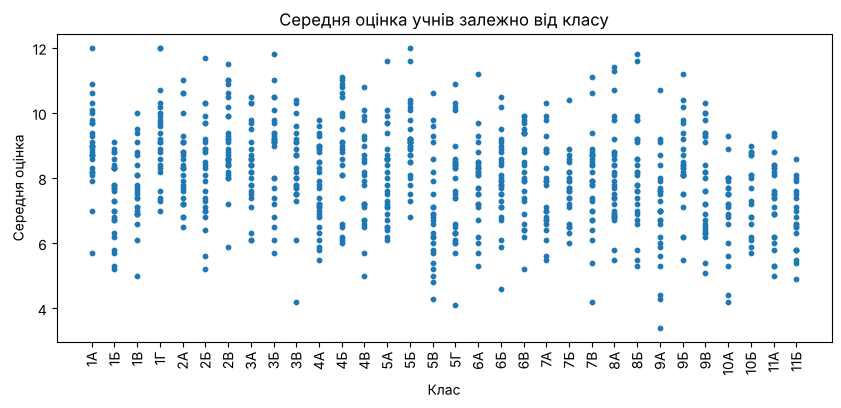

In [6]:
# d) середня оцінка учнів залежно від класу
plt.figure(figsize=(10, 4))
for i, c in enumerate(school.classes):
    plt.scatter([i] * len(c), [s.average_grade for s in c.students], s=10, color="tab:blue")
plt.xticks(range(len(school.classes)), [c.name for c in school.classes], rotation=90)
plt.title("Середня оцінка учнів залежно від класу")
plt.xlabel("Клас")
plt.ylabel("Середня оцінка")
plt.show()

## Переведення класів на рік вперед

In [7]:
print("До:", ", ".join(c.name for c in school.classes))
students_before = len(school.all_students())
graduates = sum(len(c) for c in school.classes if c.grade == 11)

school.promote_all_classes()

print("Після:", ", ".join(c.name for c in school.classes))

До: 1А, 1Б, 1В, 1Г, 2А, 2Б, 2В, 3А, 3Б, 3В, 4А, 4Б, 4В, 5А, 5Б, 5В, 5Г, 6А, 6Б, 6В, 7А, 7Б, 7В, 8А, 8Б, 9А, 9Б, 9В, 10А, 10Б, 11А, 11Б
Після: 2А, 2Б, 2В, 2Г, 3А, 3Б, 3В, 4А, 4Б, 4В, 5А, 5Б, 5В, 6А, 6Б, 6В, 6Г, 7А, 7Б, 7В, 8А, 8Б, 8В, 9А, 9Б, 10А, 10Б, 10В, 11А, 11Б


## Статистика після переведення

In [8]:
school.print_statistics()

# перевірка переведення
print()
print("1-х класів немає:", all(c.grade != 1 for c in school.classes))
print("Учнів менше на кількість випускників:",
      len(school.all_students()) == students_before - graduates)

a) Загальна кількість учнів: 795
b) Хлопці: 53.6 %, дівчата: 46.4 %
c) Середня кількість учнів у класі: 26.5
d) Максимальна кількість учнів: 31 (3В, 5А)
e) Мінімальна кількість учнів: 18 (11Б)

1-х класів немає: True
Учнів менше на кількість випускників: True
